# 3. Relative entropy and mutual information

**Cover and Thomas, Sections 2.3 and 2.4.**

**Relative entropy** (Kullback-Leibler divergence) between two probability
mass functions $p$ and $q$ on the same alphabet:

$$D(p \,\Vert \, q) = \sum_{x} p(x) \log \frac{p(x)}{q(x)} = \mathbb E_p \log \frac{p(X)}{q(X)} .$$

Conventions: $0 \log \frac00 = 0$, $0 \log \frac0q = 0$, and
$p \log \frac p0 = \infty$. So if $q(x) = 0$ somewhere that $p(x) > 0$, then
$D(p\Vert q) = \infty$.

**Mutual information** is the relative entropy between the joint distribution
and the product of the marginals:

$$I(X;Y) = \sum_{x}\sum_{y} p(x,y) \log \frac{p(x,y)}{p(x)\,p(y)}
= D\big(p(x,y) \,\Vert \, p(x)p(y)\big).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(2)

## 3.1 The definition, written out

In [2]:
def relative_entropy(p, q):
    """D(p || q) in bits. Returns infinity when q is 0 where p is not."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    if np.any((p > 0) & (q == 0)):
        return np.inf
    nz = p > 0                      # terms with p(x) = 0 contribute 0
    return float(np.sum(p[nz] * np.log2(p[nz] / q[nz])))


print("D(p||p)              =", relative_entropy([0.3, 0.7], [0.3, 0.7]))
print("D([0.5,0.5]||[1,0])  =", relative_entropy([0.5, 0.5], [1.0, 0.0]))
print("D([1,0]||[0.5,0.5])  =", relative_entropy([1.0, 0.0], [0.5, 0.5]))

D(p||p)              = 0.0
D([0.5,0.5]||[1,0])  = inf
D([1,0]||[0.5,0.5])  = 1.0


The second line shows the infinite case: $q$ assigns probability zero to an
outcome that $p$ considers possible. The third line shows that the reverse
order is perfectly finite. Relative entropy is **not symmetric**.

## 3.2 Example 2.3.1: two Bernoulli distributions

Let $p(0) = 1-r$, $p(1) = r$ and $q(0) = 1-s$, $q(1) = s$. Then

$$D(p\Vert q) = (1-r)\log\frac{1-r}{1-s} + r \log \frac rs, \qquad
D(q\Vert p) = (1-s)\log\frac{1-s}{1-r} + s \log \frac sr .$$

With $r = \tfrac12$ and $s = \tfrac14$ the book reports
$D(p\Vert q) = 1 - \tfrac12 \log 3 = 0.2075$ bit and
$D(q\Vert p) = \tfrac34 \log 3 - 1 = 0.1887$ bit.

In [3]:
r, s = 0.5, 0.25
p = np.array([1 - r, r])
q = np.array([1 - s, s])

print(f"D(p||q) = {it.relative_entropy(p, q):.6f}   book: 1 - (1/2)log2(3)  = {1 - 0.5*np.log2(3):.6f}")
print(f"D(q||p) = {it.relative_entropy(q, p):.6f}   book: (3/4)log2(3) - 1  = {0.75*np.log2(3) - 1:.6f}")
print(f"equal?  {np.isclose(it.relative_entropy(p, q), it.relative_entropy(q, p))}")

D(p||q) = 0.207519   book: 1 - (1/2)log2(3)  = 0.207519
D(q||p) = 0.188722   book: (3/4)log2(3) - 1  = 0.188722
equal?  False


The asymmetry is easiest to see as a picture. Fix $r = 1/2$ and let $s$ vary.

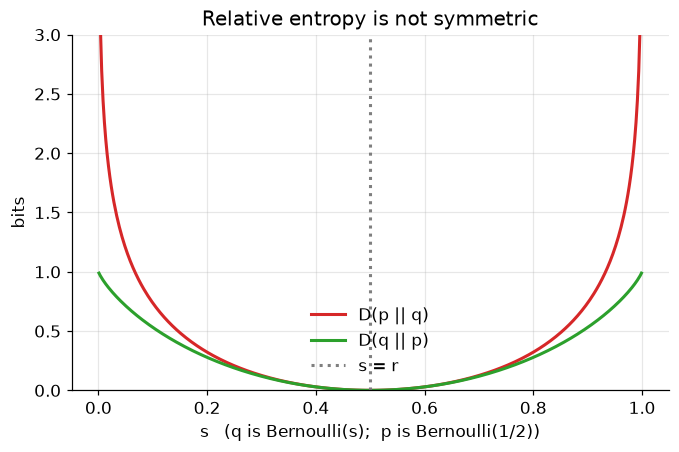

In [4]:
s_grid = np.linspace(0.001, 0.999, 400)
r_fixed = 0.5

D_pq = [it.relative_entropy([1 - r_fixed, r_fixed], [1 - s, s]) for s in s_grid]
D_qp = [it.relative_entropy([1 - s, s], [1 - r_fixed, r_fixed]) for s in s_grid]

plt.plot(s_grid, D_pq, color=it.COLORS["D"], label="D(p || q)")
plt.plot(s_grid, D_qp, color=it.COLORS["I"], label="D(q || p)")
plt.axvline(r_fixed, color=it.COLORS["bound"], linestyle=":", label="s = r")
plt.xlabel("s   (q is Bernoulli(s);  p is Bernoulli(1/2))")
plt.ylabel("bits")
plt.ylim(0, 3)
plt.title("Relative entropy is not symmetric")
plt.legend()
plt.show()

Both curves vanish only at $s = r$, and both are non-negative. That is
Theorem 2.6.3, the information inequality, proved in notebook 05. Here is a
numerical check.

In [5]:
n_tests = 5000
smallest = np.inf
zero_only_when_equal = True
for _ in range(n_tests):
    k = rng.integers(2, 8)
    a = it.random_pmf(k, rng)
    b = it.random_pmf(k, rng)
    d = it.relative_entropy(a, b)
    smallest = min(smallest, d)
    if d < 1e-12 and not np.allclose(a, b):
        zero_only_when_equal = False

it.check(f"D(p||q) >= 0 on {n_tests} random pairs", smallest >= 0,
         f"smallest value seen: {smallest:.6f}")
it.check("D(p||q) = 0 was never reached with p different from q", zero_only_when_equal)
it.check("D(p||p) = 0", it.relative_entropy(a, a) == 0)

[PASS] D(p||q) >= 0 on 5000 random pairs   smallest value seen: 0.000000
[PASS] D(p||q) = 0 was never reached with p different from q
[PASS] D(p||p) = 0


True

## 3.3 What relative entropy costs you

The book's interpretation: if the true distribution is $p$ but we build a
code for $q$, the average description length is $H(p) + D(p\Vert q)$ instead of
$H(p)$. The ideal code length for the symbol $x$ under $q$ is
$\log \frac{1}{q(x)}$ bits, so the average length is

$$\sum_x p(x) \log \frac{1}{q(x)} = H(p) + D(p\Vert q).$$

The extra $D(p\Vert q)$ bits are the price of using the wrong model.

In [6]:
p = np.array([0.5, 0.25, 0.125, 0.125])     # the truth
q = np.array([0.25, 0.25, 0.25, 0.25])      # the model we wrongly assume

length_right = float(np.sum(p * np.log2(1 / p)))     # code built for p
length_wrong = float(np.sum(p * np.log2(1 / q)))     # code built for q

print(f"H(p)                          = {it.entropy(p):.6f} bits/symbol")
print(f"average length, code for p    = {length_right:.6f}")
print(f"average length, code for q    = {length_wrong:.6f}")
print(f"difference                    = {length_wrong - length_right:.6f}")
print(f"D(p||q)                       = {it.relative_entropy(p, q):.6f}")
it.check("wasted bits per symbol = D(p||q)",
         np.isclose(length_wrong - length_right, it.relative_entropy(p, q)))

H(p)                          = 1.750000 bits/symbol
average length, code for p    = 1.750000
average length, code for q    = 2.000000
difference                    = 0.250000
D(p||q)                       = 0.250000
[PASS] wasted bits per symbol = D(p||q)


True

## 3.4 Mutual information

$$I(X;Y) = D\big(p(x,y)\,\Vert \,p(x)p(y)\big).$$

So $I(X;Y)$ measures how far the joint distribution is from the one that
would hold if $X$ and $Y$ were independent. It is zero exactly when they are
independent.

In [7]:
def mutual_information(P):
    """I(X;Y) for a joint table P[i, j] = p(x_i, y_j), in bits."""
    P = np.asarray(P, dtype=float)
    product = np.outer(P.sum(axis=1), P.sum(axis=0))    # the table p(x) p(y)
    nz = P > 0
    return float(np.sum(P[nz] * np.log2(P[nz] / product[nz])))


independent = np.outer([0.4, 0.6], [0.3, 0.7])
print("independent table:\n", np.round(independent, 4))
print("I(X;Y) =", mutual_information(independent))

dependent = np.array([[0.4, 0.0],
                      [0.0, 0.6]])
print("\nY is a function of X:\n", dependent)
print("I(X;Y) =", mutual_information(dependent),
      "   H(X) =", it.entropy(dependent.sum(axis=1)))

independent table:
 [[0.12 0.28]
 [0.18 0.42]]
I(X;Y) = 3.8441118045779005e-17

Y is a function of X:
 [[0.4 0. ]
 [0.  0.6]]
I(X;Y) = 0.9709505944546686    H(X) = 0.9709505944546686


## 3.5 Theorem 2.4.1: the five identities

$$I(X;Y) = H(X) - H(X\mid Y) = H(Y) - H(Y \mid X) = H(X) + H(Y) - H(X,Y)
= I(Y;X), \qquad I(X;X) = H(X).$$

We check them on the book's Example 2.2.1 table, for which Example 2.4.1
reports $I(X;Y) = 0.375$ bit.

In [8]:
book_table = np.array([
    [1/8,  1/16, 1/32, 1/32],
    [1/16, 1/8,  1/32, 1/32],
    [1/16, 1/16, 1/16, 1/16],
    [1/4,  0,    0,    0   ],
])
P = book_table.T

H_X  = it.entropy(it.marginal_X(P))
H_Y  = it.entropy(it.marginal_Y(P))
H_XY = it.joint_entropy(P)
H_X_g_Y = it.cond_entropy_X_given_Y(P)
H_Y_g_X = it.cond_entropy_Y_given_X(P)
I_XY = it.mutual_information(P)

print(f"I(X;Y)  from the definition      = {I_XY:.6f}     book: 0.375")
print(f"H(X) - H(X|Y)                    = {H_X - H_X_g_Y:.6f}")
print(f"H(Y) - H(Y|X)                    = {H_Y - H_Y_g_X:.6f}")
print(f"H(X) + H(Y) - H(X,Y)             = {H_X + H_Y - H_XY:.6f}")
print(f"I(Y;X)  (transposed table)       = {it.mutual_information(P.T):.6f}")
print()

it.check("I = H(X) - H(X|Y)",          np.isclose(I_XY, H_X - H_X_g_Y))
it.check("I = H(Y) - H(Y|X)",          np.isclose(I_XY, H_Y - H_Y_g_X))
it.check("I = H(X) + H(Y) - H(X,Y)",   np.isclose(I_XY, H_X + H_Y - H_XY))
it.check("I(X;Y) = I(Y;X)",            np.isclose(I_XY, it.mutual_information(P.T)))

# I(X;X): build the joint table of X with itself, which is diagonal.
pX = it.marginal_X(P)
P_XX = np.diag(pX)
it.check("I(X;X) = H(X)", np.isclose(it.mutual_information(P_XX), H_X),
         f"{it.mutual_information(P_XX):.6f} = {H_X:.6f}")

I(X;Y)  from the definition      = 0.375000     book: 0.375
H(X) - H(X|Y)                    = 0.375000
H(Y) - H(Y|X)                    = 0.375000
H(X) + H(Y) - H(X,Y)             = 0.375000
I(Y;X)  (transposed table)       = 0.375000

[PASS] I = H(X) - H(X|Y)
[PASS] I = H(Y) - H(Y|X)
[PASS] I = H(X) + H(Y) - H(X,Y)
[PASS] I(X;Y) = I(Y;X)
[PASS] I(X;X) = H(X)   1.750000 = 1.750000


True

## 3.6 Figure 2.2: the Venn diagram

The five quantities fit together as two overlapping sets. The union is
$H(X,Y)$, the intersection is $I(X;Y)$, and the two crescents are
$H(X\mid Y)$ and $H(Y \mid X)$.

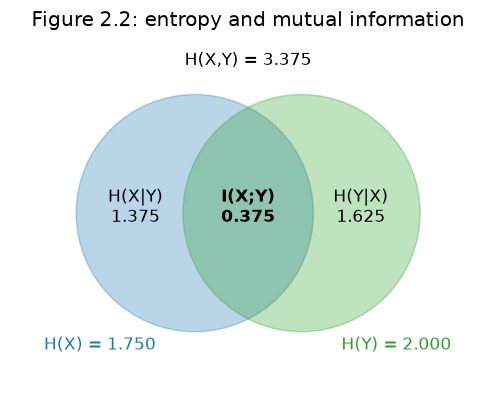

In [9]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))

left = plt.Circle((-0.45, 0), 1.0, color=it.COLORS["H"], alpha=0.30)
right = plt.Circle((0.45, 0), 1.0, color=it.COLORS["I"], alpha=0.30)
ax.add_patch(left)
ax.add_patch(right)

ax.text(-0.95, 0.05, f"H(X|Y)\n{H_X_g_Y:.3f}", ha="center", va="center")
ax.text(0.0,  0.05, f"I(X;Y)\n{I_XY:.3f}", ha="center", va="center", weight="bold")
ax.text(0.95, 0.05, f"H(Y|X)\n{H_Y_g_X:.3f}", ha="center", va="center")
ax.text(-1.25, -1.15, f"H(X) = {H_X:.3f}", ha="center", color=it.COLORS["H"])
ax.text(1.25, -1.15, f"H(Y) = {H_Y:.3f}", ha="center", color=it.COLORS["I"])
ax.text(0.0, 1.25, f"H(X,Y) = {H_XY:.3f}", ha="center")

ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Figure 2.2: entropy and mutual information")
plt.show()

## 3.7 A worked channel: the binary symmetric channel

Send a bit $X$ through a channel that flips it with probability $\varepsilon$.
If $X$ is 1 with probability $a$, the joint table is

$$p(x,y) = p(x)\, p(y \mid x), \qquad
p(y\mid x) = \begin{cases} 1-\varepsilon & y = x \\ \varepsilon & y \neq x .\end{cases}$$

For a uniform input the mutual information is $1 - H(\varepsilon)$ bits, which
is the capacity of this channel (Chapter 7). It is 1 bit for a perfect channel
and 0 bits when $\varepsilon = 1/2$, where the output tells you nothing.
Notice that $\varepsilon = 1$ is a *perfect* channel too: it always lies, so
you simply flip the answer back.

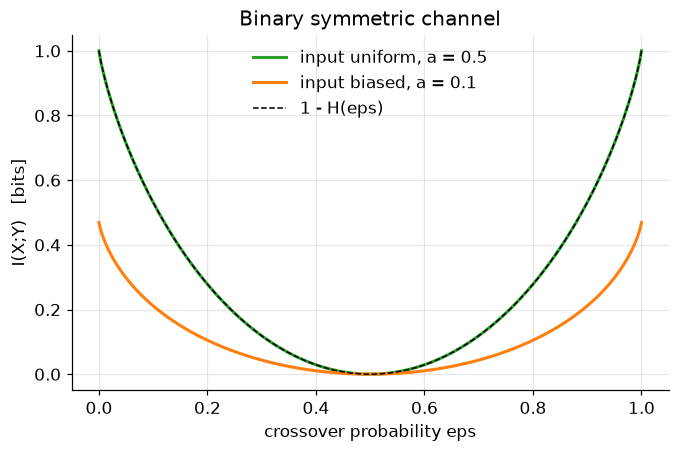

In [10]:
def bsc_joint(a, eps):
    """Joint table for X ~ Bernoulli(a) through a channel that flips with prob eps."""
    pX = np.array([1 - a, a])
    channel = np.array([[1 - eps, eps],
                        [eps, 1 - eps]])        # channel[i, j] = p(Y = j | X = i)
    return pX[:, None] * channel


eps_grid = np.linspace(0, 1, 401)
I_uniform = [it.mutual_information(bsc_joint(0.5, e)) for e in eps_grid]
I_biased = [it.mutual_information(bsc_joint(0.1, e)) for e in eps_grid]

plt.plot(eps_grid, I_uniform, color=it.COLORS["I"], label="input uniform, a = 0.5")
plt.plot(eps_grid, I_biased, color=it.COLORS["cond"], label="input biased, a = 0.1")
plt.plot(eps_grid, 1 - it.binary_entropy(eps_grid), "k--", linewidth=1,
         label="1 - H(eps)")
plt.xlabel("crossover probability eps")
plt.ylabel("I(X;Y)   [bits]")
plt.title("Binary symmetric channel")
plt.legend()
plt.show()

### A slider for the channel

In [11]:
def show_bsc(a=0.5, eps=0.1):
    P = bsc_joint(a, eps)
    H_X = it.entropy(it.marginal_X(P))
    I = it.mutual_information(P)
    plt.figure(figsize=(7.0, 3.0))
    plt.barh(["information"], [I], color=it.COLORS["I"], label=f"I(X;Y) = {I:.4f}")
    plt.barh(["information"], [H_X - I], left=[I], color=it.COLORS["cond"],
             label=f"H(X|Y) = {H_X - I:.4f}")
    plt.xlim(0, 1.05)
    plt.xlabel("bits")
    plt.title(f"a = {a:.2f},  eps = {eps:.2f},  H(X) = {H_X:.4f} bits")
    plt.legend(loc="lower right")
    plt.grid(axis="y", visible=False)
    plt.show()


try:
    from ipywidgets import interact, FloatSlider
    interact(show_bsc,
             a=FloatSlider(min=0.01, max=0.99, step=0.01, value=0.5),
             eps=FloatSlider(min=0.0, max=1.0, step=0.01, value=0.1))
except ImportError:
    show_bsc(0.5, 0.1)
    print("(install ipywidgets to get the sliders)")

interactive(children=(FloatSlider(value=0.5, description='a', max=0.99, min=0.01, step=0.01), FloatSlider(valu…

## 3.8 Mutual information estimated from data

Send many bits through the channel, count the pairs, and estimate $I(X;Y)$
from the counts.

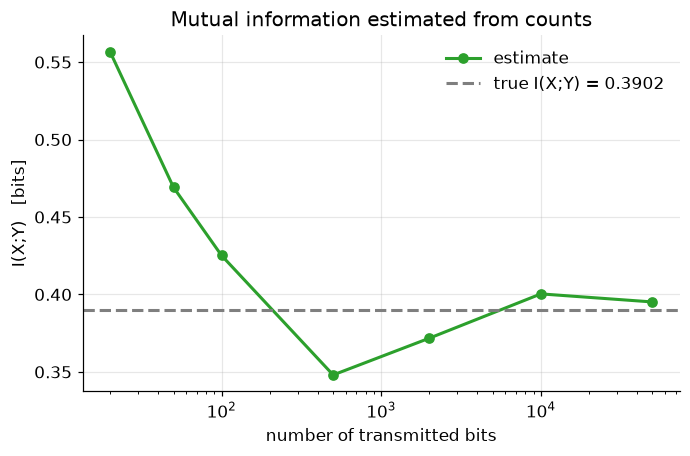

With few samples the estimate is too LARGE: random fluctuations look
like dependence. This is the opposite of the bias seen for entropy.


In [12]:
a, eps = 0.5, 0.15
P = bsc_joint(a, eps)
I_true = it.mutual_information(P)

sizes = [20, 50, 100, 500, 2000, 10_000, 50_000]
estimates = []
for n in sizes:
    flat = rng.choice(4, size=n, p=P.ravel())
    counts = np.bincount(flat, minlength=4).reshape(2, 2)
    estimates.append(it.mutual_information(counts / n))

plt.semilogx(sizes, estimates, "o-", color=it.COLORS["I"], label="estimate")
plt.axhline(I_true, color=it.COLORS["bound"], linestyle="--",
            label=f"true I(X;Y) = {I_true:.4f}")
plt.xlabel("number of transmitted bits")
plt.ylabel("I(X;Y)   [bits]")
plt.title("Mutual information estimated from counts")
plt.legend()
plt.show()

print("With few samples the estimate is too LARGE: random fluctuations look")
print("like dependence. This is the opposite of the bias seen for entropy.")

## Things to try

1. In Section 3.3, make `q` close to `p` and watch the wasted bits shrink.
   Then set one entry of `q` to zero and see the average length blow up.
2. In Section 3.7, replace the symmetric channel by the **binary erasure
   channel**: with probability $\alpha$ the output is a third symbol "?",
   otherwise the output equals the input. Show that $I(X;Y) = (1-\alpha)H(X)$.
3. Show numerically that $D(p\Vert q)$ does not satisfy the triangle inequality:
   find three distributions with $D(p\Vert r) > D(p\Vert q) + D(q\Vert r)$.
4. In Section 3.8, plot the estimate of $I(X;Y)$ when $X$ and $Y$ are truly
   independent. The true value is 0, but the estimate is always positive.
   How fast does it decay with $n$?